import Libraries

In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

copy datasets paths

In [4]:
train_dir = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train"
val_dir = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation"
test_dir = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test"

Count Images in Each Class

In [5]:
def count_images(directory):
    categories = os.listdir(directory)

    category_count = {category: 
                     len(os.listdir(os.path.join(directory , category ))) for category in categories}

    return category_count

count images 

In [6]:
train_count = count_images(train_dir)
test_count = count_images(test_dir)
validation_count = count_images(val_dir)

In [7]:
print(f"Train sample count : {train_count}\n")

Train sample count : {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}



In [8]:
print(f"Test sample count : {test_count}\n")

Test sample count : {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}



In [9]:
print(f"Validation sample count : {validation_count}")


Validation sample count : {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


create DataFrame

In [10]:
df_train = pd.DataFrame(list(train_count.items()), columns=['Vegetable', 'Train Count'])
df_test = pd.DataFrame(list(test_count.items()), columns=['Vegetable', 'Test Count'])
df_validation = pd.DataFrame(list(validation_count.items()), columns=['Vegetable', 'Validation Count'])

In [11]:
df = pd.merge(df_train, df_test, on='Vegetable')
df = pd.merge(df, df_validation, on='Vegetable')

In [12]:
df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


Visualize Class Distribution

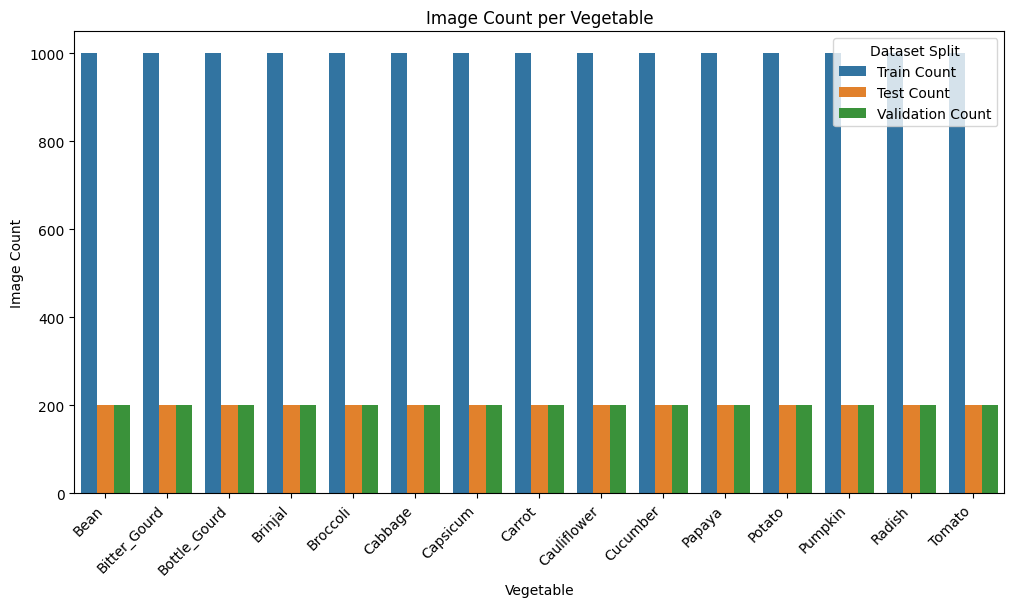

In [13]:
df_melted = df.melt(id_vars='Vegetable', 
                    value_vars=['Train Count', 'Test Count', 'Validation Count'], 
                    var_name='Dataset Split', 
                    value_name='Image Count')

# Set figure size
plt.figure(figsize=(12, 6))

# Create bar plot
sns.barplot(data=df_melted, x='Vegetable', y='Image Count', hue='Dataset Split')

# Customize the plot
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.xlabel('Vegetable')
plt.ylabel('Image Count')
plt.title('Image Count per Vegetable')

# Show the plot
plt.legend(title='Dataset Split')
plt.show()

Image Preprocessing and Augmentation

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define ImageDataGenerator for training (with augmentation)
train_datagen = ImageDataGenerator(
    rescale = 1./225 ,
    rotation_range = 10 ,
    width_shift_range=0.1,    
    height_shift_range=0.1, 
    shear_range=0.1,          
    zoom_range=0.1,   
    horizontal_flip=True,     
    validation_split=0.2      # Split dataset (80% train, 20% validation)
)
            
# Define ImageDataGenerator for validation (only rescaling)
val_datagen = ImageDataGenerator(
    rescale=1./255,  
    validation_split=0.2
)

# Load training dataset
train_ds = train_datagen.flow_from_directory(
    "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",  
    seed=48,
    shuffle=True
)

# Load validation dataset (from the same train directory but validation split)
val_ds = val_datagen.flow_from_directory(
    "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",  
    seed=48
)

Found 12000 images belonging to 15 classes.
Found 600 images belonging to 15 classes.


 Build the CNN Model

**Convolution Block 1**


Conv2D with 32 filters

3x3 kernel

ReLU activation

Input shape = 224 x 224 x 3

MaxPooling2D




**Convolution Block 2**


Conv2D with 64 filters

3x3 kernel

ReLU activation

MaxPooling2D




**Convolution Block 3**


Conv2D with 128 filters

3x3 kernel

ReLU activation

MaxPooling2D


**Fully Connected Layers**


Flatten

Dense layer with 512 neurons and ReLU activation

Dropout with rate 0.5

Output Dense layer with 15 neurons and Softmax activation

**Compile the Model**

Optimizer: Adam

Loss Function: Categorical Crossentropy

Metric: Accuracy


**model summary**

In [15]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Conv2D , Dropout , Dense , Flatten , MaxPooling2D
                                    

In [16]:
model = Sequential([
    Conv2D(32 , (3,3) , activation = "relu" , input_shape= (224 , 224 , 3) ) ,
    MaxPooling2D(2 , 2),
    Conv2D(64 , (3,3) , activation = "relu" ),
    MaxPooling2D(2 , 2),
    Conv2D(128 , (3,3) , activation = "relu" ),
    MaxPooling2D(2 , 2), 
    Flatten(),
    Dense(512 , activation = "relu"),
    Dropout(0.5),
    Dense(15 , activation = "softmax")
])
# Compile the model
model.compile(
    optimizer = "adam",
    loss = 'categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

***briefly explain:***


**Number of convolutional layers.**

we have 2 convolutional layers being seprated with 2 features extraction layers
which create feature mapping

**Purpose of pooling layers.**

two make feature extraction and reduce number of features

**Purpose of dropout.**

two prevent the model from knowing the data (data leakage) and overfitting

**Why softmax is used in the output layer.**

because it's a classifaction Task

***Train the Model***

Training dataset

Validation dataset

20 epochs maximum

**EarlyStopping callback**

The EarlyStopping callback should:

Monitor validation loss

Use patience = 5

Restore best weights


In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor = "val_loss" ,
    patience = 5 ,
    restore_best_weights = True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs = 20 ,
    callbacks = [early_stop]
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1044s 3s/step - accuracy: 0.4765 - loss: 1.5595 - val_accuracy: 0.7567 - val_loss: 0.8189
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 173s 461ms/step - accuracy: 0.7337 - loss: 0.8050 - val_accuracy: 0.8500 - val_loss: 0.4857
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 176s 469ms/step - accuracy: 0.8156 - loss: 0.5649 - val_accuracy: 0.8450 - val_loss: 0.4655
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 178s 474ms/step - accuracy: 0.8534 - loss: 0.4474 - val_accuracy: 0.9267 - val_loss: 0.2901
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 179s 476ms/step - accuracy: 0.8851 - loss: 0.3667 - val_accuracy: 0.9450 - val_loss: 0.2138
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 168s 447ms/step - accuracy: 0.8951 - loss: 0.3370 - val_accuracy: 0.8500 - val_loss: 0.4710
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 165s 439ms/step - accuracy: 0.9114 - loss: 0.2831 - val_accuracy: 0.9283 - val_loss: 0.2030
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 162s 431ms/step - accuracy: 0.9223 - l

explain why EarlyStopping is useful:
- it monitor the metric we want to get the best
- it prevent eating the resources and prevent model from overlapping and overfitting
- it restore the best weight after the model make sure that there is no improving

**Evaluate the Model**


In [18]:
# Evaluate on training set
train_loss, train_acc = model.evaluate(train_ds)
print(f"Train Accuracy: {train_acc * 100:.2f}%")

# Evaluate on validation set
val_loss, val_acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

375/375 ━━━━━━━━━━━━━━━━━━━━ 159s 425ms/step - accuracy: 0.9871 - loss: 0.0503
Train Accuracy: 98.71%
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - accuracy: 0.9833 - loss: 0.0607
Validation Accuracy: 98.33%


Is there a large difference between training accuracy and validation accuracy?

no

What does this tell you about overfitting?

there is no overfitting


Plot Accuracy and Loss Curves

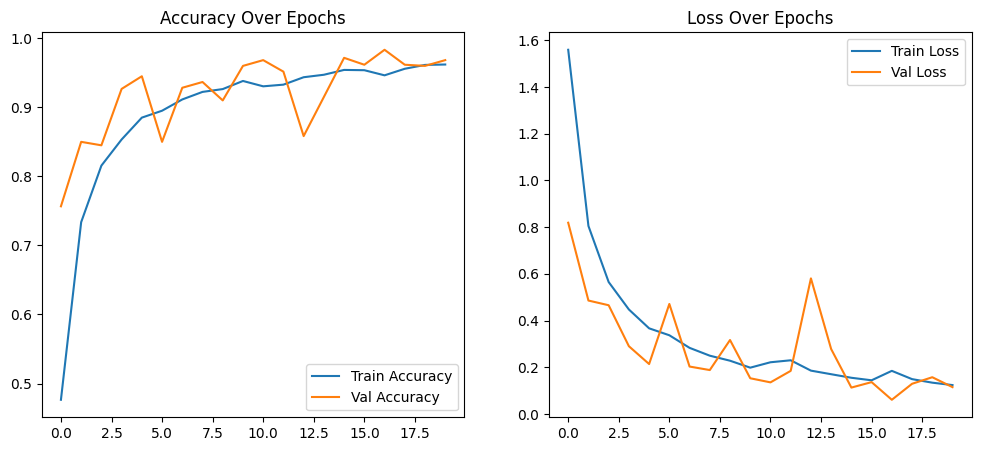

In [19]:

# Extract values
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

# Plot Accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Train Accuracy")
plt.plot(epochs_range, val_acc, label="Val Accuracy")
plt.legend()
plt.title("Accuracy Over Epochs")

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Train Loss")
plt.plot(epochs_range, val_loss, label="Val Loss")
plt.legend()
plt.title("Loss Over Epochs")

plt.show()


some predction

In [21]:
import numpy as np

# Get true labels and predictions
y_true = []
y_pred = []

for i, (images, labels) in enumerate(val_ds):
    if i == 20:
        break

    preds = model.predict(images)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


In [22]:
from sklearn.metrics import classification_report

# Get class names from dataset
class_names = list(val_ds.class_indices.keys())

# Print classification report
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

        Bean       1.00      1.00      1.00        39
Bitter_Gourd       1.00      1.00      1.00        39
Bottle_Gourd       1.00      1.00      1.00        46
     Brinjal       0.92      1.00      0.96        36
    Broccoli       0.95      0.98      0.97        43
     Cabbage       0.96      1.00      0.98        46
    Capsicum       1.00      0.97      0.99        38
      Carrot       1.00      1.00      1.00        34
 Cauliflower       1.00      1.00      1.00        41
    Cucumber       1.00      0.98      0.99        45
      Papaya       0.95      0.93      0.94        45
      Potato       1.00      1.00      1.00        48
     Pumpkin       0.98      0.96      0.97        46
      Radish       1.00      1.00      1.00        47
      Tomato       1.00      0.95      0.97        39

    accuracy                           0.98       632
   macro avg       0.98      0.98      0.98       632
weighted avg       0.98   